In [462]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression 
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neighbors  import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier



In [412]:

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [414]:
train.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [416]:
train.shape



(891, 12)

In [418]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [420]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [422]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

<Axes: >

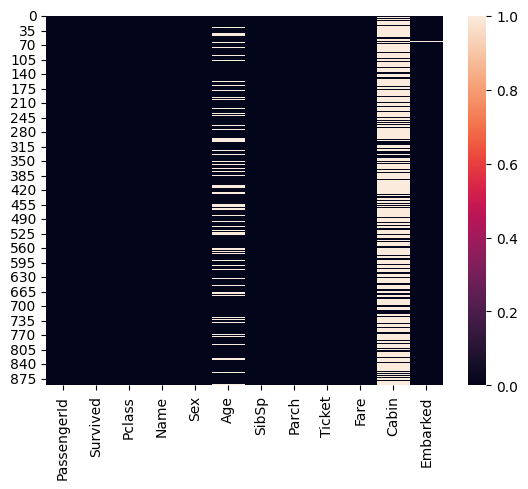

In [424]:
sns.heatmap(train.isnull())

## 2- Clean Data 


In [427]:
def clean(d):
      d.drop(['Cabin', 'Name','Ticket', 'Fare','Embarked'], axis=1 , inplace = True)
      d.Age = train.Age.fillna(train.Age.median())
      d.dropna()
      return d
    


In [429]:
clean(train)

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch
0,1,0,3,male,22.0,1,0
1,2,1,1,female,38.0,1,0
2,3,1,3,female,26.0,0,0
3,4,1,1,female,35.0,1,0
4,5,0,3,male,35.0,0,0
...,...,...,...,...,...,...,...
886,887,0,2,male,27.0,0,0
887,888,1,1,female,19.0,0,0
888,889,0,3,female,28.0,1,2
889,890,1,1,male,26.0,0,0


In [431]:
clean(test)

,PassengerId,Pclass,Sex,Age,SibSp,Parch
0,892,3,male,22.0,0,0
1,893,3,female,38.0,1,0
2,894,2,male,26.0,0,0
3,895,3,male,35.0,0,0
4,896,3,female,35.0,1,1
...,...,...,...,...,...,...
413,1305,3,male,28.0,0,0
414,1306,1,female,44.0,0,0
415,1307,3,male,28.0,0,0
416,1308,3,male,34.0,0,0


<Axes: >

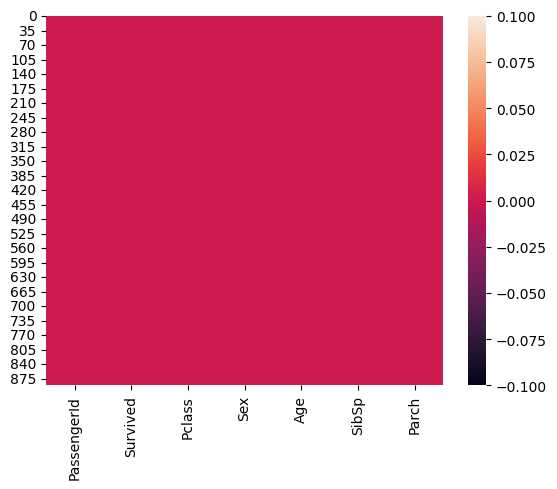

In [433]:
sns.heatmap(train.isnull())

In [434]:
train["Sex"] = train["Sex"].map({"male": 1, "female": 0})


## 3- Analysis 


In [438]:
co=train.corr()

<Axes: >

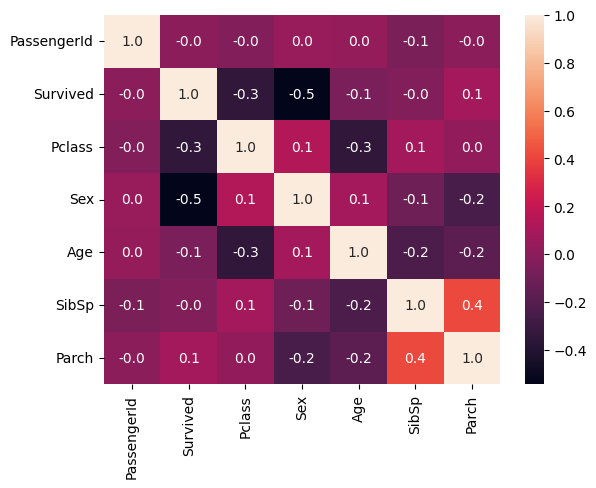

In [442]:
sns.heatmap(co, annot=True, fmt = '.1f')

In [443]:
train.Survived.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

<Axes: ylabel='count'>

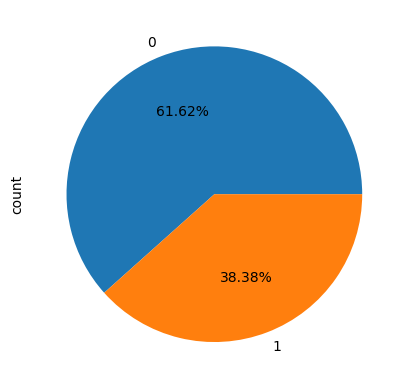

In [444]:
train.Survived.value_counts().plot.pie(autopct='%0.2f%%')

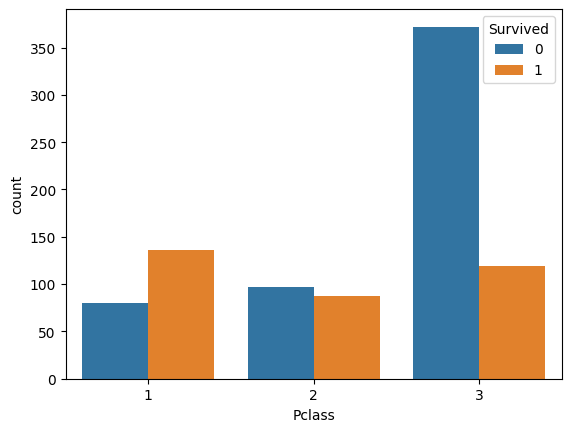

In [448]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Pclass", hue="Survived", data=train)
plt.show()


<Axes: xlabel='Age', ylabel='Count'>

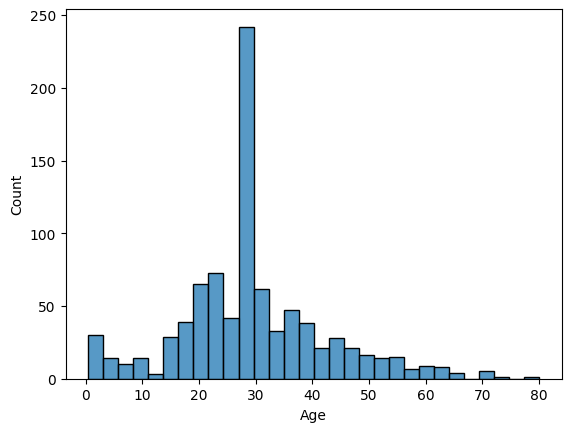

In [449]:
sns.histplot(train.Age)

In [452]:
train

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch
0,1,0,3,1,22.0,1,0
1,2,1,1,0,38.0,1,0
2,3,1,3,0,26.0,0,0
3,4,1,1,0,35.0,1,0
4,5,0,3,1,35.0,0,0
...,...,...,...,...,...,...,...
886,887,0,2,1,27.0,0,0
887,888,1,1,0,19.0,0,0
888,889,0,3,0,28.0,1,2
889,890,1,1,1,26.0,0,0


## 4 - Create Model 


In [455]:
x = train.drop(['Survived'], axis =1)
y =train.Survived

In [457]:
x_train ,x_test , y_train , y_test = train_test_split(x,y,train_size = .8)

In [466]:
model1 = DecisionTreeClassifier()
model1.fit(x_train , y_train)

DecisionTreeClassifier()

In [470]:
pre = model1.predict( x_test)

In [474]:
from sklearn.metrics import accuracy_score

accuracy_score(pre,y_test)

0.7597765363128491

In [496]:
accuracies = []

In [498]:
def all(model):
    model.fit(x_train , y_train)
    pre = model.predict( x_test)
    accuracy=accuracy_score(pre,y_test)
    print('accuracy=', accuracy)
    accuracies.append(accuracy)

In [518]:
model1 = DecisionTreeClassifier()
all(model1)

accuracy= 0.7597765363128491


In [520]:
model2= LogisticRegression()
all(model2)

accuracy= 0.776536312849162


In [522]:
model3 = RandomForestClassifier()
all(model2)

accuracy= 0.776536312849162


In [524]:
model4= DecisionTreeClassifier()
all(model3)

accuracy= 0.7988826815642458


In [525]:
model5= GaussianNB()
all(model5)

accuracy= 0.7821229050279329


In [528]:
model6= SVC()
all(model6)

accuracy= 0.6089385474860335


In [537]:
print(len(Algorithms))  # Vérifier la longueur de la liste Algorithms
print(len(accuracies))  # Vérifier la longueur de la liste accuracies


6
11


In [539]:
accuracies = accuracies[:len(Algorithms)]


In [541]:
Algorithms =['LR' , 'RF' , 'GB' , 'DT','NB','svc']
new = pd.DataFrame({'Algorithms':Algorithms ,'accuracies':accuracies})

In [543]:
new

,Algorithms,accuracies
0,LR,0.776536
1,RF,0.804469
2,GB,0.765363
3,DT,0.782123
4,NB,0.608939
5,svc,0.759777
